In [1]:
import pandas as pd
import matplotlib.pyplot as plt

paises = pd.read_csv('../data/paises.csv', sep=';', encoding='utf-8')
space = pd.read_csv('../data/space.csv', sep=';', encoding='utf-8')

paises['Country'] = paises['Country'].str.strip()
paises['Region'] = paises['Region'].str.strip()
space['Company Name'] = space['Company Name'].str.strip()
space['Status Mission'] = space['Status Mission'].str.strip()

# Questão 1

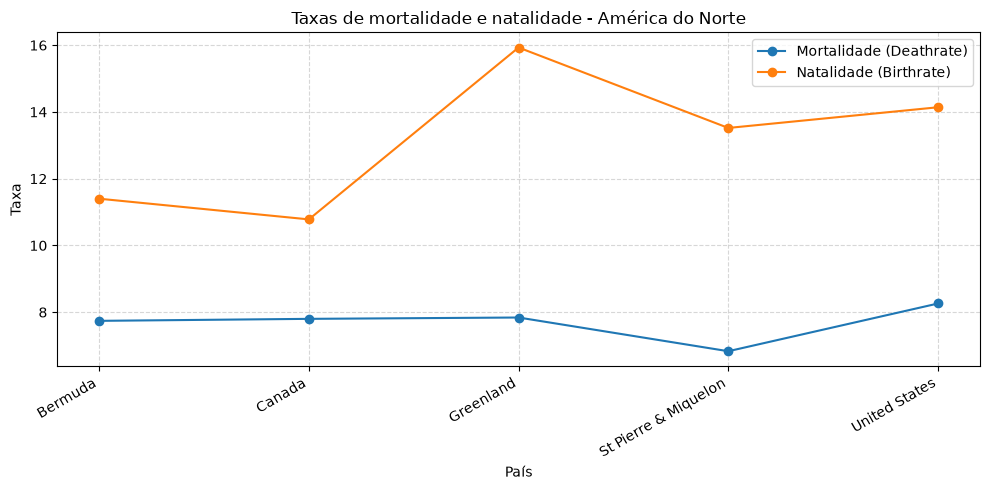

In [7]:
america_norte = paises[paises['Region'] == 'NORTHERN AMERICA']

plt.figure(figsize=(10, 5))
plt.plot(america_norte['Country'], america_norte['Deathrate'], marker='o', label='Mortalidade (Deathrate)')
plt.plot(america_norte['Country'], america_norte['Birthrate'], marker='o', label='Natalidade (Birthrate)')
plt.title('Taxas de mortalidade e natalidade - América do Norte')
plt.xlabel('País')
plt.ylabel('Taxa')
plt.xticks(rotation=30, ha='right')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Questão 2

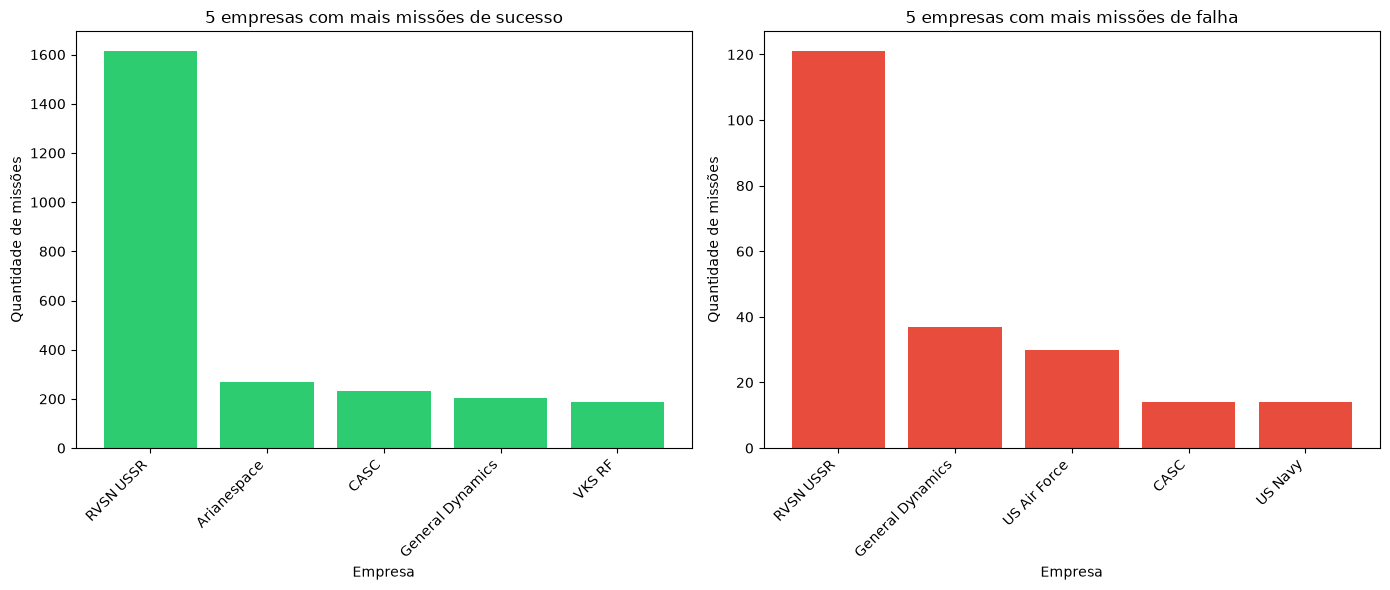

In [3]:
top_sucesso = space[space['Status Mission'] == 'Success']['Company Name'].value_counts().head(5)
top_falha = space[space['Status Mission'] == 'Failure']['Company Name'].value_counts().head(5)

fig, eixos = plt.subplots(1, 2, figsize=(14, 6))

eixos[0].bar(top_sucesso.index, top_sucesso.values, color='#2ecc71')
eixos[0].set_title('5 empresas com mais missões de sucesso')
eixos[0].set_xlabel('Empresa')
eixos[0].set_ylabel('Quantidade de missões')
eixos[0].set_xticks(range(len(top_sucesso)))
eixos[0].set_xticklabels(top_sucesso.index, rotation=45, ha='right')

eixos[1].bar(top_falha.index, top_falha.values, color='#e74c3c')
eixos[1].set_title('5 empresas com mais missões de falha')
eixos[1].set_xlabel('Empresa')
eixos[1].set_ylabel('Quantidade de missões')
eixos[1].set_xticks(range(len(top_falha)))
eixos[1].set_xticklabels(top_falha.index, rotation=45, ha='right')

plt.tight_layout()
plt.show()

# Questão 3

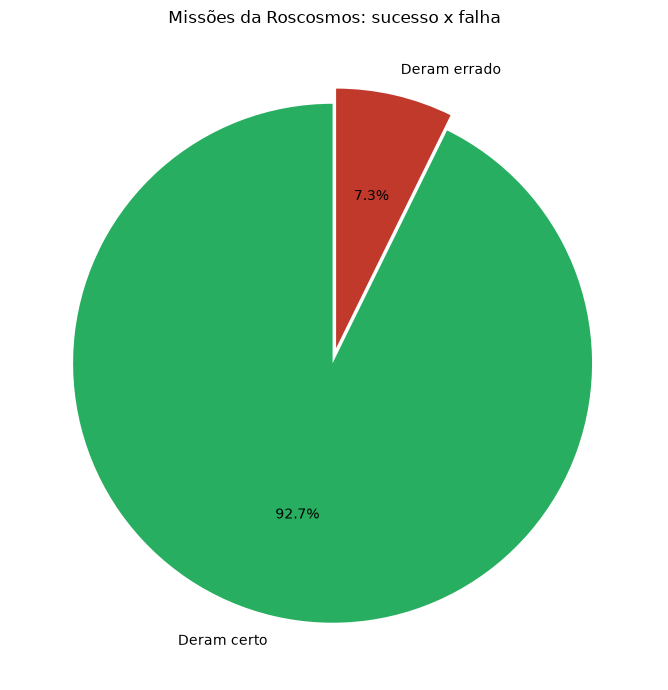

In [4]:
roscosmos = space[space['Company Name'] == 'Roscosmos']
certo = (roscosmos['Status Mission'] == 'Success').sum()
errado = (roscosmos['Status Mission'] != 'Success').sum()

plt.figure(figsize=(7, 7))
plt.pie(
    [certo, errado],
    labels=['Deram certo', 'Deram errado'],
    autopct='%1.1f%%',
    colors=['#27ae60', '#c0392b'],
    startangle=90,
    explode=(0.03, 0.03),
)
plt.title('Missões da Roscosmos: sucesso x falha')
plt.tight_layout()
plt.show()

# Questão 4

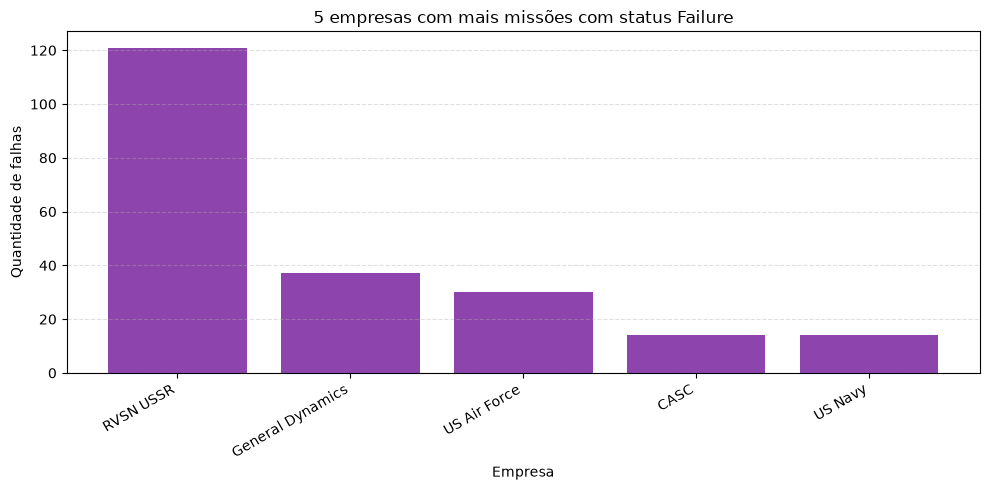

In [5]:
top_failure = space[space['Status Mission'] == 'Failure']['Company Name'].value_counts().head(5)

plt.figure(figsize=(10, 5))
plt.bar(top_failure.index, top_failure.values, color='#8e44ad')
plt.title('5 empresas com mais missões com status Failure')
plt.xlabel('Empresa')
plt.ylabel('Quantidade de falhas')
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Questão 5

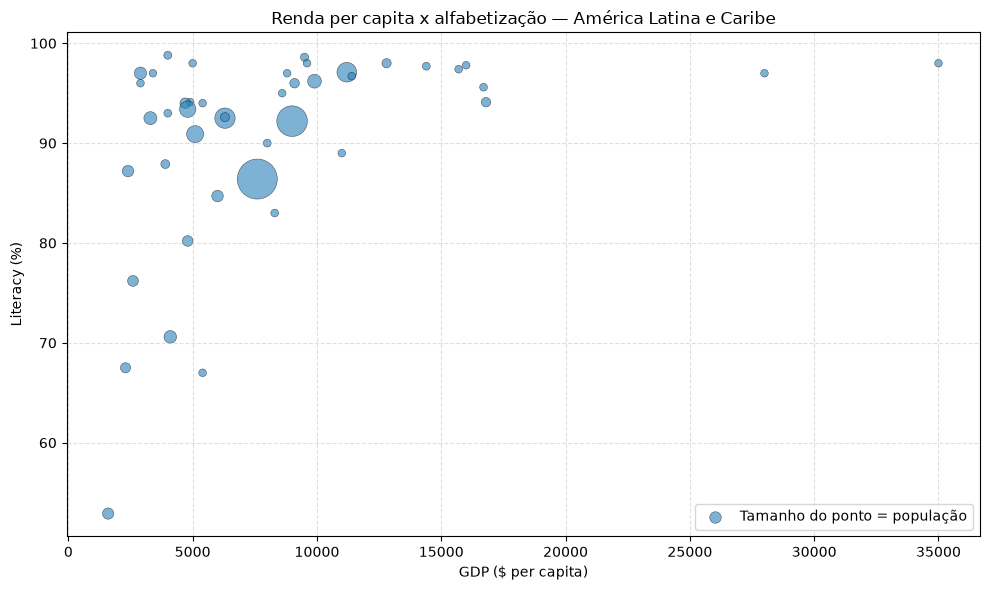

In [6]:
america_latina = paises[
    (paises['Region'] == 'LATIN AMER. & CARIB') &
    (paises['Literacy (%)'] > 0)
]

tamanhos = (america_latina['Population'] / america_latina['Population'].max()) * 800 + 30

plt.figure(figsize=(10, 6))
plt.scatter(
    america_latina['GDP ($ per capita)'],
    america_latina['Literacy (%)'],
    s=tamanhos,
    alpha=0.6,
    c='#2980b9',
    edgecolors='black',
    linewidths=0.4,
    label='Tamanho do ponto = população',
)
plt.title('Renda per capita x alfabetização — América Latina e Caribe')
plt.xlabel('GDP ($ per capita)')
plt.ylabel('Literacy (%)')
plt.legend(markerscale=0.4)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()